# Stereo depth and calibration, hands on

This notebook walks one real clear (shot 37 of `clears_nov10`) from raw pixels to a predicted landing spot, using the project's own code in `vision/`.

1. Two eyes, one bird: what disparity is
2. Disparity to depth: `Z = f · B / d`
3. Why far birds are noisy: depth error grows with distance squared
4. The calibration: projecting the court onto the image
5. Lens distortion
6. From pixels to court positions, and the landing fit
7. Experiments to try

Run cells top to bottom (Shift+Enter). Everything reads files; nothing is written.

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "vision"))

import flight_model
from experiment.landing_experiment import load_shots
from calibrate_net import COURT_TO_INTERNAL_AXES, StereoModel, overlay_polylines
from court_3d import StereoCourt
from frames import FrameSource, crop_eye, load_frame_times

SESSION = REPO / "data" / "recordings" / "clears_nov10"
SHOT = 37
TRACKS_FILE = "bird_tracks_yolo11n_crop.json"
RESULTS_FILE = "landing_experiment_yolo11n_crop.json"

calibration = json.loads((SESSION / "net_calibration.json").read_text())
track = {t["shot"]: t for t in json.loads((SESSION / TRACKS_FILE).read_text())}[SHOT]
results = json.loads((SESSION / RESULTS_FILE).read_text())
source = FrameSource(str(SESSION / f"{track['take']}.avi"))
court = StereoCourt(calibration)

focal_px = calibration["intrinsics"]["focal_px"]
baseline_m = calibration["intrinsics"]["baseline_m"]
stereo = np.array(track["stereo"])


def show(images, titles, width=16):
    figure, axes = plt.subplots(1, len(images), figsize=(width, width / len(images) * 0.6))
    for axis, image, title in zip(np.atleast_1d(axes), images, titles):
        axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        axis.set_title(title)
        axis.axis("off")
    plt.tight_layout()
    plt.show()


print(f"shot {SHOT}: {track['take']}, hit at frame {track['hit_frame']}, bird matched in both eyes on {len(stereo)} frames")
print(f"focal length {focal_px} px, baseline {baseline_m * 100:.0f} cm")

shot 37: take_007, hit at frame 818, bird matched in both eyes on 19 frames
focal length 699.8 px, baseline 12 cm


## 1. Two eyes, one bird

The ZED has two cameras 12 cm apart. Each frame holds both views side by side. The same bird appears in both, but **shifted sideways**: that shift is the *disparity*, and it is the only depth cue we use.

The dashed line is the same image row in both eyes. The right eye sits about 12 px lower (the two sensors aren't perfectly aligned), so the bird is on a line just under it.

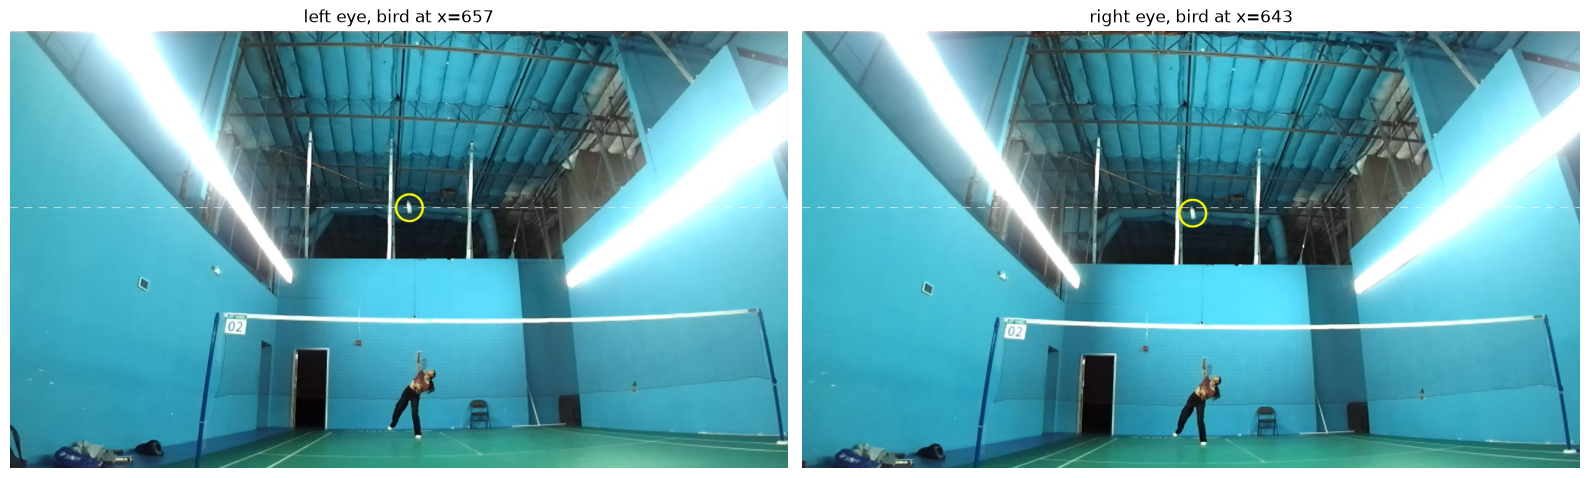

disparity = 657.2 - 642.6 = 14.5 px
row difference = 9.6 px (calibrated offset 12.21 px)


In [2]:
POINT_INDEX = 6
frame, left_x, left_y, right_x, right_y = stereo[POINT_INDEX]
stereo_frame = source.read(int(frame))
left_eye, right_eye = crop_eye(stereo_frame, "left").copy(), crop_eye(stereo_frame, "right").copy()
for image, x, y in ((left_eye, left_x, left_y), (right_eye, right_x, right_y)):
    cv2.circle(image, (int(x), int(y)), 22, (0, 255, 255), 2, cv2.LINE_AA)
    for column in range(0, image.shape[1], 24):
        cv2.line(image, (column, int(left_y)), (column + 12, int(left_y)), (255, 255, 255), 1)

show([left_eye, right_eye], [f"left eye, bird at x={left_x:.0f}", f"right eye, bird at x={right_x:.0f}"])
print(f"disparity = {left_x:.1f} - {right_x:.1f} = {left_x - right_x:.1f} px")
print(f"row difference = {right_y - left_y:.1f} px (calibrated offset {calibration['intrinsics']['right_eye_vertical_offset_px']} px)")

## 2. Disparity to depth

For two parallel cameras, similar triangles give

```
Z = f · B / d
```

- `Z`: distance from the camera (m)
- `f`: focal length in pixels (~700 px here)
- `B`: baseline, the distance between the eyes (0.12 m)
- `d`: disparity in pixels

Small disparity = far away. The project's `StereoCourt.camera_points_m` does the same thing but first removes lens distortion, so the two curves below differ slightly.

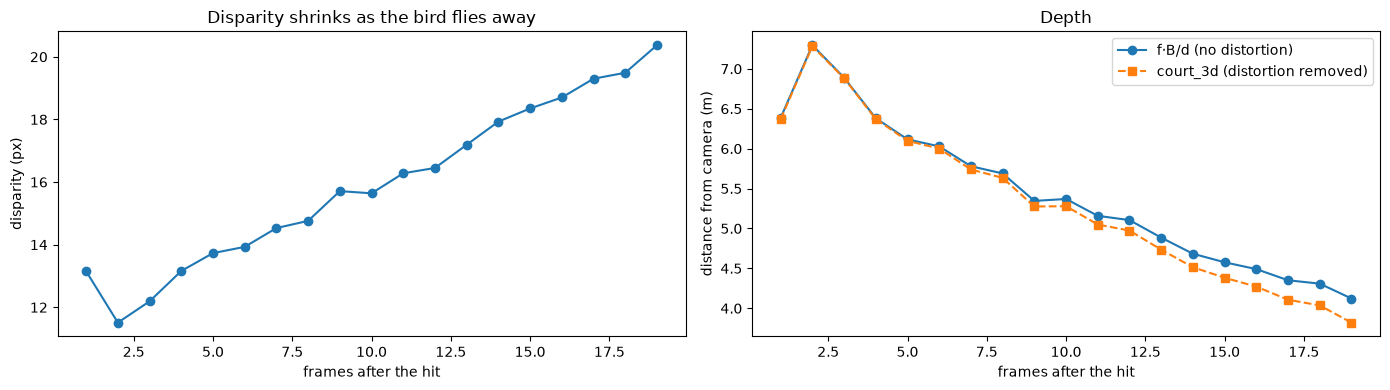

In [3]:
frames_after_hit = stereo[:, 0] - track["hit_frame"]
disparity_px = stereo[:, 1] - stereo[:, 3]
simple_depth_m = focal_px * baseline_m / disparity_px
project_depth_m = court.camera_points_m(stereo[:, 1:3], stereo[:, 3:5])[:, 2]

figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(14, 4))
left_axis.plot(frames_after_hit, disparity_px, "o-")
left_axis.set(xlabel="frames after the hit", ylabel="disparity (px)", title="Disparity shrinks as the bird flies away")
right_axis.plot(frames_after_hit, simple_depth_m, "o-", label="f·B/d (no distortion)")
right_axis.plot(frames_after_hit, project_depth_m, "s--", label="court_3d (distortion removed)")
right_axis.set(xlabel="frames after the hit", ylabel="distance from camera (m)", title="Depth")
right_axis.legend()
plt.tight_layout()
plt.show()

## 3. Why far birds are noisy

Differentiate `Z = f·B/d`: one pixel of disparity error changes depth by about

```
ΔZ ≈ Z² / (f · B)
```

It grows with the **square** of distance. The bird is found to within a pixel or so, but at 8–10 m away that pixel is worth tens of centimetres. This is the biggest limit of a 12 cm baseline.

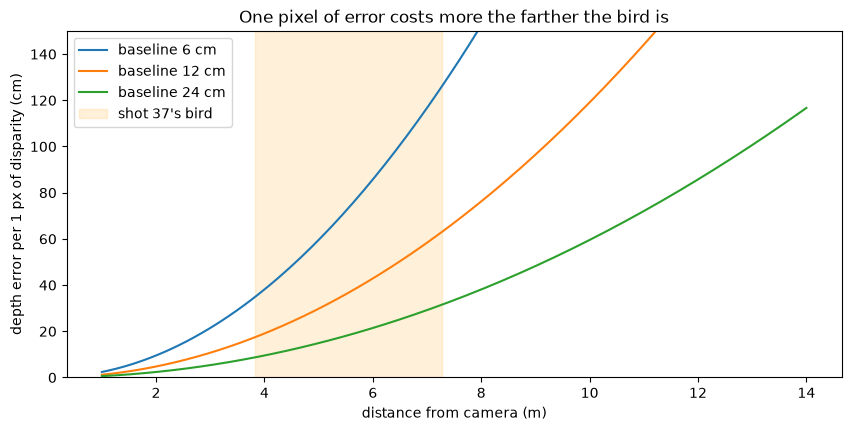

at  3 m: 1 px =  10.7 cm of depth
at  6 m: 1 px =  42.9 cm of depth
at  9 m: 1 px =  96.5 cm of depth
at 12 m: 1 px = 171.5 cm of depth


In [4]:
distances_m = np.linspace(1, 14, 200)
figure, axis = plt.subplots(figsize=(10, 4.5))
for baseline in (0.06, 0.12, 0.24):
    axis.plot(distances_m, distances_m ** 2 / (focal_px * baseline) * 100, label=f"baseline {baseline * 100:.0f} cm")
axis.axvspan(project_depth_m.min(), project_depth_m.max(), color="orange", alpha=0.15, label=f"shot {SHOT}'s bird")
axis.set(xlabel="distance from camera (m)", ylabel="depth error per 1 px of disparity (cm)", ylim=(0, 150),
         title="One pixel of error costs more the farther the bird is")
axis.legend()
plt.show()
for distance in (3, 6, 9, 12):
    print(f"at {distance:>2} m: 1 px = {distance ** 2 / (focal_px * baseline_m) * 100:5.1f} cm of depth")

## 4. The calibration

`vision/calibrate_net.py` found where the camera is and how its lens behaves by matching clicked court points (net posts, lines) to their known positions. The result is in `net_calibration.json`:

- **Extrinsics** (where the camera is): a rotation and translation from court to camera.
- **Intrinsics** (the lens): focal length, principal point (image centre), distortion `k1`, `k2`.

A good test of a calibration: draw the court lines with it. If the drawn lines sit on the real lines, the model is right.

{
 "camera_position_court_cm": [
  -141.0,
  406.7,
  68.6
 ],
 "camera_angles_deg": {
  "yaw_from_facing_net": 2.61,
  "pitch_up": 15.01,
  "roll": -0.64
 }
}
{
 "focal_px": 699.8,
 "focal_was_fitted": true,
 "principal_point_px": [
  640.0,
  429.3
 ],
 "baseline_m": 0.12,
 "right_eye_vertical_offset_px": 12.21,
 "lens_distortion_k1_k2": [
  -0.1771,
  0.0385
 ],
 "lens_distortion_model": "radial: pixel = focal * normalized * (1 + k1 r^2 + k2 r^4) + centre"
}


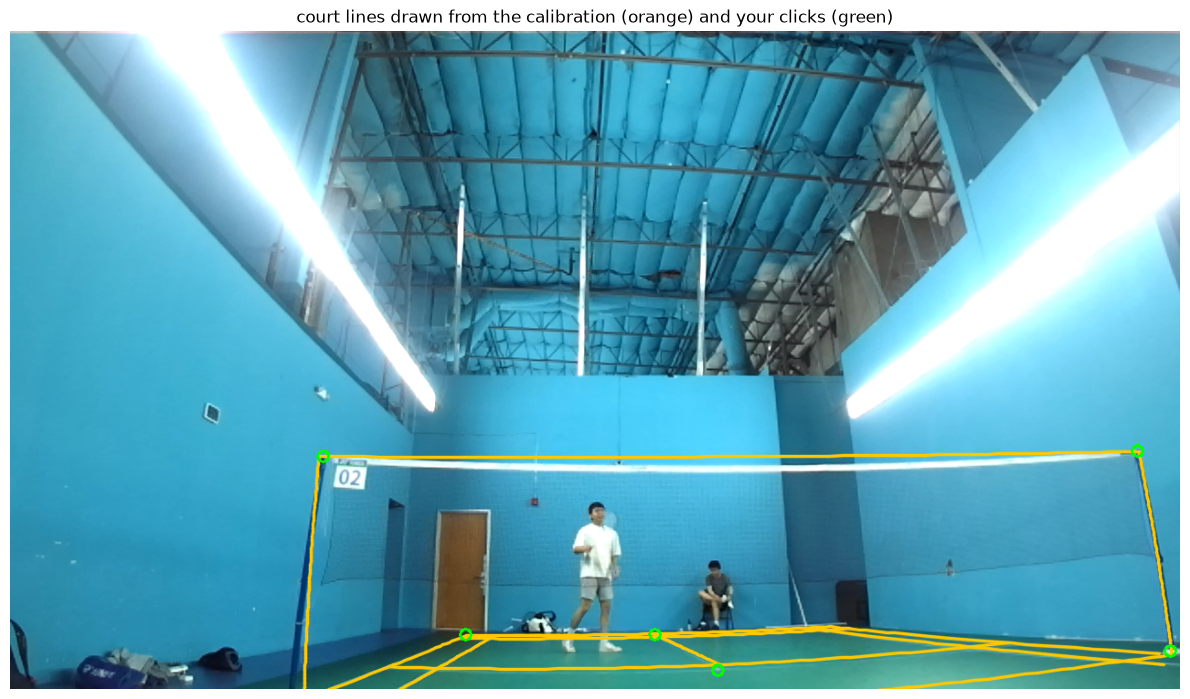

In [5]:
print(json.dumps({key: calibration[key] for key in ("camera_position_court_cm", "camera_angles_deg")}, indent=1))
print(json.dumps(calibration["intrinsics"], indent=1))

rotation_internal_to_camera = np.array(calibration["camera_from_court"]["matrix"]) @ COURT_TO_INTERNAL_AXES
rvec, _ = cv2.Rodrigues(rotation_internal_to_camera)
tvec = np.array(calibration["camera_from_court"]["translation_m"])
intrinsics = calibration["intrinsics"]
lens = StereoModel(intrinsics["focal_px"], intrinsics["right_eye_vertical_offset_px"], *intrinsics["lens_distortion_k1_k2"],
                   principal_row=intrinsics["principal_point_px"][1])

snapshot = cv2.imread(str(SESSION / "calibration.png"))
left_snapshot = crop_eye(snapshot, "left").copy() if snapshot.shape[1] > 1280 else snapshot.copy()
for polyline in overlay_polylines(rvec.ravel(), tvec, lens, "left"):
    cv2.polylines(left_snapshot, [np.array(polyline, np.int32)], False, (0, 200, 255), 2, cv2.LINE_AA)
for point in calibration["reprojection"]:
    if point["eye"] == "left":
        cv2.circle(left_snapshot, tuple(int(v) for v in point["clicked"]), 6, (0, 255, 0), 2)
show([left_snapshot], ["court lines drawn from the calibration (orange) and your clicks (green)"], width=12)

In [6]:
print(f"{'point':<24}{'eye':<7}{'error (px)':>10}")
for point in sorted(calibration["reprojection"], key=lambda p: -p["error_px"]):
    print(f"{point['name']:<24}{point['eye']:<7}{point['error_px']:>10.1f}")

point                   eye    error (px)
hitter_service_center   right         7.5
hitter_service_center   left          6.6
hitter_back_left        right         5.6
right_post_base         left          4.7
right_post_base         right         4.6
left_post_top           left          4.0
left_post_top           right         3.0
hitter_back_center      right         2.0
right_post_top          left          1.9
right_post_top          right         1.8
hitter_back_left        left          1.7
hitter_back_center      left          1.6


## 5. Lens distortion

Wide lenses bend straight lines, more so toward the corners. The model is

```
pixel = centre + f · p · (1 + k1·r² + k2·r⁴)
```

where `p` is the ideal (pinhole) position and `r` its distance from the centre in focal-length units. Negative `k1` = barrel distortion: points are pulled toward the centre.

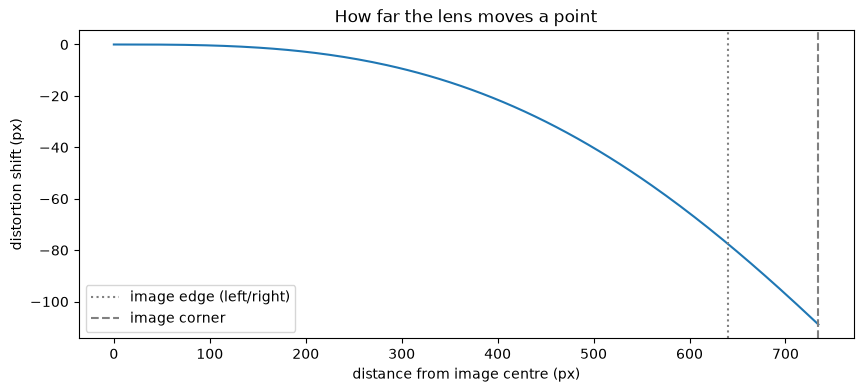

at the image corner the lens pulls a point 109 px toward the centre


In [7]:
k1, k2 = intrinsics["lens_distortion_k1_k2"]
pixel_radius = np.linspace(0, np.hypot(640, 360), 200)
r = pixel_radius / focal_px
shift_px = pixel_radius * (k1 * r ** 2 + k2 * r ** 4)

figure, axis = plt.subplots(figsize=(10, 4))
axis.plot(pixel_radius, shift_px)
axis.axvline(640, color="gray", linestyle=":", label="image edge (left/right)")
axis.axvline(np.hypot(640, 360), color="gray", linestyle="--", label="image corner")
axis.set(xlabel="distance from image centre (px)", ylabel="distortion shift (px)", title="How far the lens moves a point")
axis.legend()
plt.show()
print(f"at the image corner the lens pulls a point {abs(shift_px[-1]):.0f} px toward the centre")

## 6. From pixels to the court, then the landing

`StereoCourt.court_points_cm` chains it all: undistort → triangulate → rotate into court axes (x from the middle line, y from the net, z height, cm).

`landing_experiment.py` then fits a flight model (gravity + air drag) to those 3D points and runs it forward to the floor, then applies a small correction learned on the training shots.

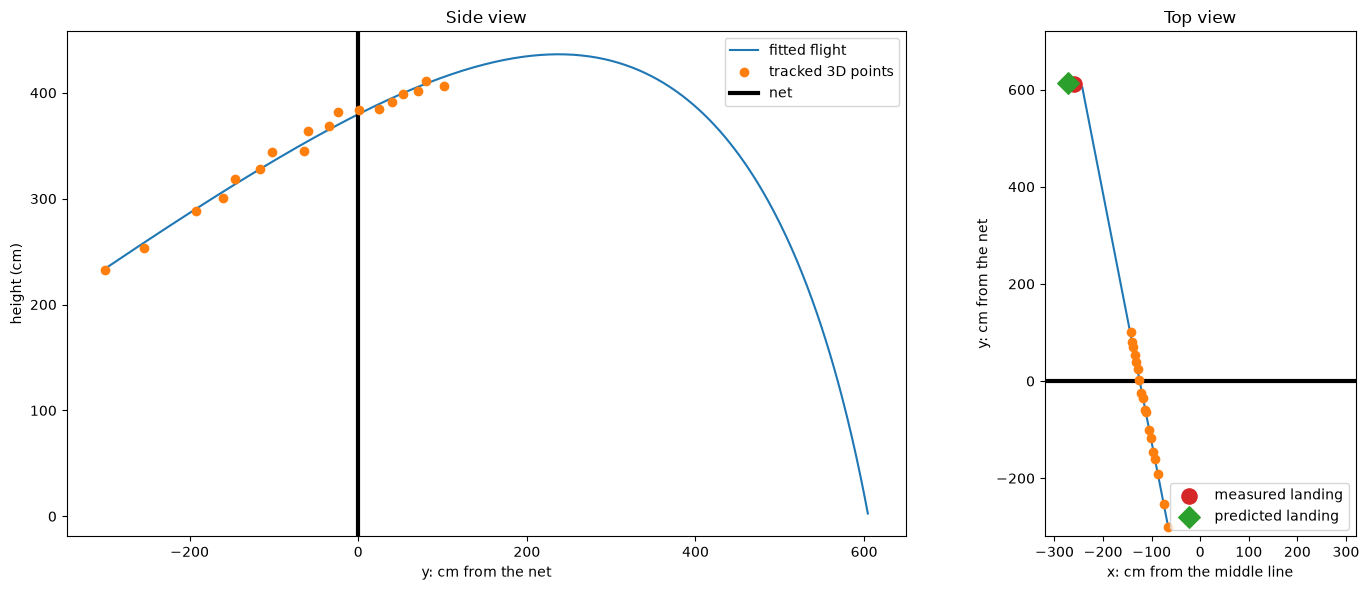

launch speed 26.3 m/s, predicted [-272.  613.], actual [-260.  612.], miss 12 cm


In [8]:
shots, tracks_for_fit = load_shots(str(SESSION), TRACKS_FILE)
take_times = {track["take"]: load_frame_times(str(SESSION / f"{track['take']}.avi"))[0]}
times_s, points_m = flight_model.observed_flight(str(SESSION), court, shots[SHOT], tracks_for_fit[SHOT], take_times)
drag = flight_model.drag_per_metre(results["terminal_speed_m_s"])
start_position, start_velocity = flight_model.fit_flight(times_s, points_m, drag)
physics_landing_cm = flight_model.landing_point(start_position, start_velocity, drag)[:2] * 100
predicted_cm = flight_model.apply_correction(np.array(results["correction"]), physics_landing_cm[None, :])[0]
actual_cm = np.array([results["landing_x_sign"] * float(shots[SHOT]["landing_x"]), float(shots[SHOT]["landing_y"])])

flight_times = np.linspace(0, 2.5, 300)
path_m = flight_model.positions_at(start_position, start_velocity, drag, flight_times)
path_m = path_m[path_m[:, 2] >= 0]
observed_cm, path_cm = points_m * 100, path_m * 100

figure, (side, top) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.5, 1]})
side.plot(path_cm[:, 1], path_cm[:, 2], color="tab:blue", label="fitted flight")
side.scatter(observed_cm[:, 1], observed_cm[:, 2], color="tab:orange", zorder=3, label="tracked 3D points")
side.axvline(0, color="black", linewidth=3, label="net")
side.set(xlabel="y: cm from the net", ylabel="height (cm)", title="Side view")
side.legend()
top.plot(path_cm[:, 0], path_cm[:, 1], color="tab:blue")
top.scatter(observed_cm[:, 0], observed_cm[:, 1], color="tab:orange", zorder=3)
top.scatter(*actual_cm, s=120, color="tab:red", marker="o", label="measured landing", zorder=4)
top.scatter(*predicted_cm, s=120, color="tab:green", marker="D", label="predicted landing", zorder=4)
top.axhline(0, color="black", linewidth=3)
top.set(xlabel="x: cm from the middle line", ylabel="y: cm from the net", title="Top view")
top.set(xlim=(-320, 320), ylim=(-320, 720))
top.set_aspect("equal")
top.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"launch speed {np.linalg.norm(start_velocity):.1f} m/s, predicted {predicted_cm.round()}, actual {actual_cm}, "
      f"miss {np.linalg.norm(predicted_cm - actual_cm):.0f} cm")

## 7. Experiments to try

`landing_for` reruns section 6's chain with a modified calibration or noisy pixels, so you can see what each piece is worth. Some ideas:

- Change the baseline from 12.0 to 12.5 cm. How far does the landing move?
- Change the focal length by 2%.
- Add 0.5 px of random noise to every pixel and repeat 50 times. How wide is the spread?
- Drop the first 3 or last 3 tracked points. Which end matters more?

In [9]:
def landing_for(baseline_scale=1.0, focal_scale=1.0, pixel_noise_px=0.0, drop_first=0, drop_last=0, seed=0):
    changed = json.loads(json.dumps(calibration))
    changed["intrinsics"]["baseline_m"] *= baseline_scale
    changed["intrinsics"]["focal_px"] *= focal_scale
    changed_court = StereoCourt(changed)
    changed_track = dict(tracks_for_fit[SHOT])
    points = np.array(changed_track["stereo"], float)
    points = points[drop_first:len(points) - drop_last]
    points[:, 1:] += np.random.default_rng(seed).normal(0, pixel_noise_px, points[:, 1:].shape)
    changed_track["stereo"] = points.tolist()
    flight = flight_model.observed_flight(str(SESSION), changed_court, shots[SHOT], changed_track, take_times)
    position, velocity = flight_model.fit_flight(*flight, drag)
    physics = flight_model.landing_point(position, velocity, drag)[:2] * 100
    return flight_model.apply_correction(np.array(results["correction"]), physics[None, :])[0]


baseline_landing = landing_for()
for label, landing in (("baseline 12.5 cm", landing_for(baseline_scale=12.5 / 12)),
                       ("focal +2%", landing_for(focal_scale=1.02)),
                       ("drop first 3 points", landing_for(drop_first=3)),
                       ("drop last 3 points", landing_for(drop_last=3))):
    print(f"{label:<22} landing moves {np.linalg.norm(landing - baseline_landing):5.1f} cm")

baseline 12.5 cm       landing moves   2.8 cm


focal +2%              landing moves   6.3 cm
drop first 3 points    landing moves   3.0 cm
drop last 3 points     landing moves   1.8 cm


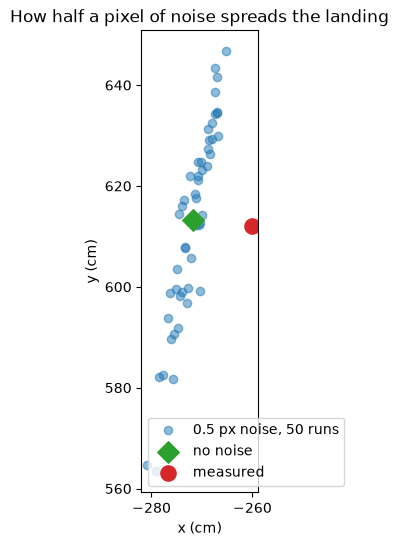

spread (std): x 3.7 cm, y 19.4 cm


In [10]:
noisy = np.array([landing_for(pixel_noise_px=0.5, seed=seed) for seed in range(50)])
figure, axis = plt.subplots(figsize=(6, 6))
axis.scatter(noisy[:, 0], noisy[:, 1], alpha=0.5, label="0.5 px noise, 50 runs")
axis.scatter(*baseline_landing, color="tab:green", marker="D", s=120, label="no noise")
axis.scatter(*actual_cm, color="tab:red", s=120, label="measured")
axis.set(xlabel="x (cm)", ylabel="y (cm)", title="How half a pixel of noise spreads the landing")
axis.set_aspect("equal")
axis.legend()
plt.show()
print(f"spread (std): x {noisy[:, 0].std():.1f} cm, y {noisy[:, 1].std():.1f} cm")